# Hillstrom Email Marketing Experiment — Team Analysis
**Applied Statistics and Data Science I · EN.553.413/613**

**Source:** [Kevin Hillstrom's MineThatData E-Mail Analytics Challenge (2008)](https://blog.minethatdata.com/2008/03/)

64,000 customers who had bought something in the past 12 months were randomly assigned to one of three groups: they received a **Men's** merchandise email, a **Women's** merchandise email, or **no email**. Their activity was then tracked for the two weeks after the campaign.

| Column | Description |
|---|---|
| `recency` | Months since last purchase |
| `history_segment` | Binned dollars spent in the past year |
| `history` | Dollars spent in the past year |
| `mens` | 1 = bought men's merchandise in the past year |
| `womens` | 1 = bought women's merchandise in the past year |
| `zip_code` | Urban, Suburban, or Rural (spelled `Surburban` in the raw data) |
| `newbie` | 1 = new customer in the past 12 months |
| `channel` | Channels the customer bought from in the past year (Phone, Web, Multichannel) |
| `segment` | Assigned group: Mens E-Mail, Womens E-Mail, No E-Mail |
| `visit` | 1 = visited the website in the following two weeks |
| `conversion` | 1 = made a purchase in the following two weeks |
| `spend` | Dollars spent in the following two weeks |

Sections 1–2 are the course starter (loading and first plots). **Section 3 is our analysis:** every number and chart on our slides is computed there, in slide order, and each chart is saved to `figures/`. Section 4 is the conclusion and section 5 runs sanity checks on the key functions.

> The first run downloads the data (internet required) and saves it in a local `data/` folder.

## 1. Load the data

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import requests

DATA = Path('data')
DATA.mkdir(exist_ok=True)
CSV_PATH = DATA / 'hillstrom_2008.csv'
URL = 'https://raw.githubusercontent.com/AdityaDabrase/ab-testing-email-marketing/main/data/raw/hillstrom.csv'

if not CSV_PATH.is_file():
    r = requests.get(URL, timeout=120)
    r.raise_for_status()
    CSV_PATH.write_bytes(r.content)

df = pd.read_csv(CSV_PATH)
print(df.shape)
df.head()

(64000, 12)


,recency,history_segment,history,mens,womens,zip_code,newbie,channel,segment,visit,conversion,spend
0,10,2) $100 - $200,142.44,1,0,Surburban,0,Phone,Womens E-Mail,0,0,0.0
1,6,3) $200 - $350,329.08,1,1,Rural,1,Web,No E-Mail,0,0,0.0
2,7,2) $100 - $200,180.65,0,1,Surburban,1,Web,Womens E-Mail,0,0,0.0
3,9,5) $500 - $750,675.83,1,0,Rural,1,Web,Mens E-Mail,0,0,0.0
4,2,1) $0 - $100,45.34,1,0,Urban,0,Web,Womens E-Mail,0,0,0.0


In [2]:
df.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
recency,64000.0,NaN,NaN,NaN,5.763734,3.507592,1.0,2.0,6.0,9.0,12.0
history_segment,64000,7,1) $0 - $100,22970,NaN,NaN,NaN,NaN,NaN,NaN,NaN
history,64000.0,NaN,NaN,NaN,242.085656,256.158608,29.99,64.66,158.11,325.6575,3345.93
mens,64000.0,NaN,NaN,NaN,0.551031,0.497393,0.0,0.0,1.0,1.0,1.0
womens,64000.0,NaN,NaN,NaN,0.549719,0.497526,0.0,0.0,1.0,1.0,1.0
zip_code,64000,3,Surburban,28776,NaN,NaN,NaN,NaN,NaN,NaN,NaN
newbie,64000.0,NaN,NaN,NaN,0.50225,0.499999,0.0,0.0,1.0,1.0,1.0
channel,64000,3,Web,28217,NaN,NaN,NaN,NaN,NaN,NaN,NaN
segment,64000,3,Womens E-Mail,21387,NaN,NaN,NaN,NaN,NaN,NaN,NaN
visit,64000.0,NaN,NaN,NaN,0.146781,0.35389,0.0,0.0,0.0,0.0,1.0


## 2. A first look

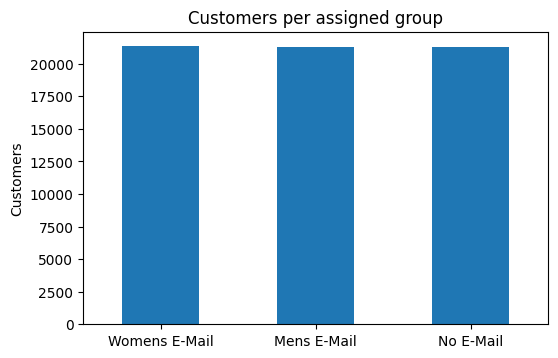

In [3]:
fig, ax = plt.subplots(figsize=(6, 3.8))
df['segment'].value_counts().plot.bar(ax=ax, rot=0)
ax.set(xlabel='', ylabel='Customers', title='Customers per assigned group')
plt.show()

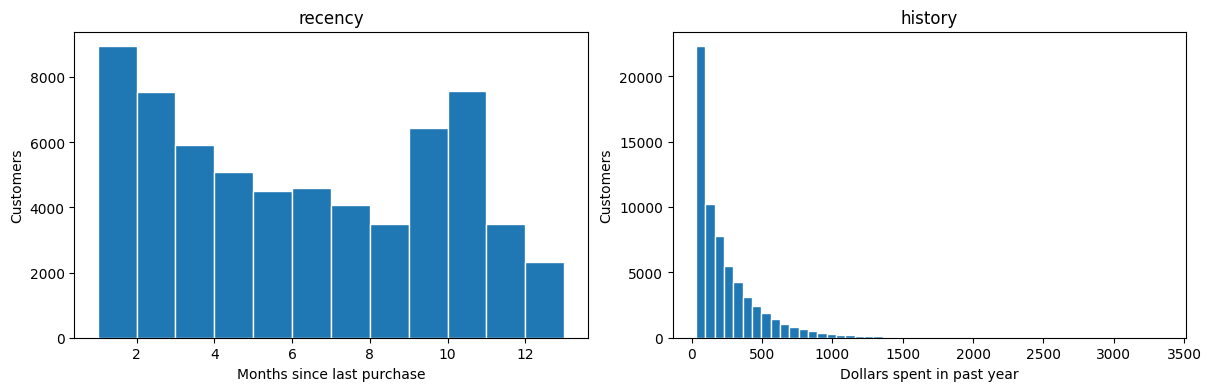

In [4]:
fig, axs = plt.subplots(1, 2, figsize=(12, 3.8), constrained_layout=True)
axs[0].hist(df['recency'], bins=range(1, 14), edgecolor='white')
axs[0].set(xlabel='Months since last purchase', ylabel='Customers', title='recency')
axs[1].hist(df['history'], bins=50, edgecolor='white')
axs[1].set(xlabel='Dollars spent in past year', ylabel='Customers', title='history')
plt.show()

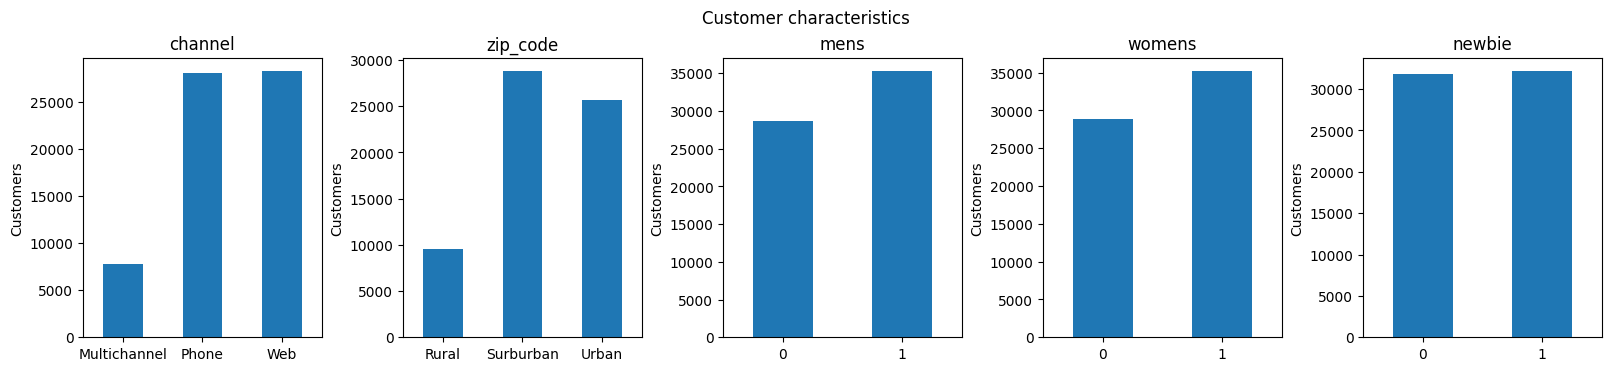

In [5]:
cats = ['channel', 'zip_code', 'mens', 'womens', 'newbie']
fig, axs = plt.subplots(1, 5, figsize=(16, 3.6), constrained_layout=True)
for ax, col in zip(axs, cats):
    df[col].value_counts().sort_index().plot.bar(ax=ax, rot=0)
    ax.set(title=col, xlabel='', ylabel='Customers')
fig.suptitle('Customer characteristics')
plt.show()

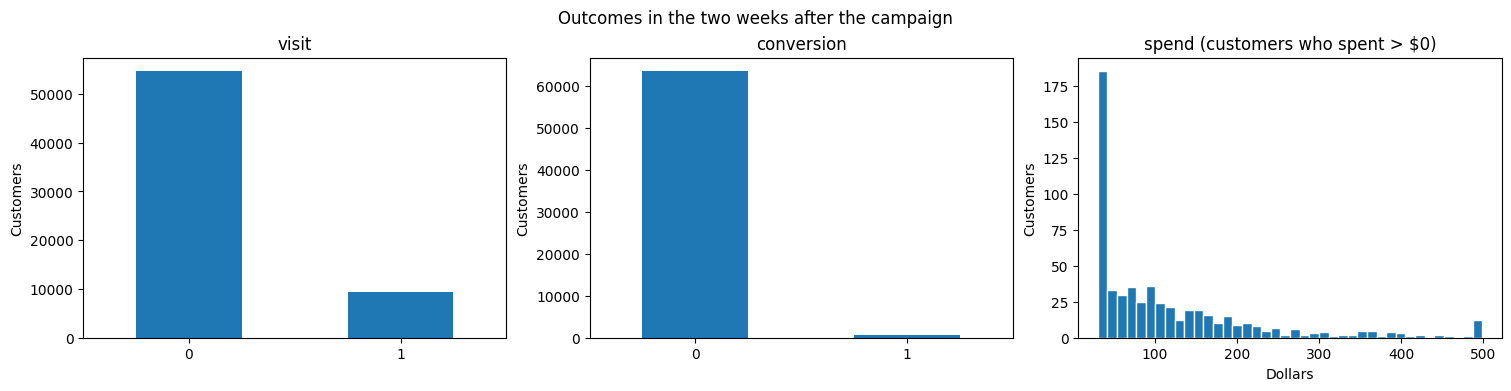

In [6]:
fig, axs = plt.subplots(1, 3, figsize=(15, 3.8), constrained_layout=True)
for ax, col in zip(axs[:2], ['visit', 'conversion']):
    df[col].value_counts().sort_index().plot.bar(ax=ax, rot=0)
    ax.set(title=col, xlabel='', ylabel='Customers')
axs[2].hist(df.loc[df['spend'] > 0, 'spend'], bins=40, edgecolor='white')
axs[2].set(xlabel='Dollars', ylabel='Customers', title='spend (customers who spent > $0)')
fig.suptitle('Outcomes in the two weeks after the campaign')
plt.show()

## 3. Our analysis (added to the starter)
**Question:** does matching the email to a customer's past purchases (women's email for women's-only buyers, men's email for men's-only buyers) increase spend beyond sending the best single email to everyone?

Every number and chart on the slides is computed below, in the same order as the slides (charts are saved to `figures/`). Run all cells from the top.

In [7]:
import numpy as np
from scipy import stats
df['zip_code'] = df['zip_code'].replace({'Surburban': 'Suburban'})   # fix the typo in the raw file
ARMS = ['No E-Mail', 'Mens E-Mail', 'Womens E-Mail']
t = df.segment.map({a: i for i, a in enumerate(ARMS)}).to_numpy()     # 0 none, 1 men's, 2 women's
y = df.spend.to_numpy(float)

import matplotlib
import matplotlib.ticker as mticker
FIGURES = Path('figures'); FIGURES.mkdir(exist_ok=True)       # charts used on the slides
ARM_COLORS = {'No E-Mail': '#7a7a7a', 'Mens E-Mail': '#1b6ca8', 'Womens E-Mail': '#d1495b'}
ARM_LABELS = {'No E-Mail': 'No email', 'Mens E-Mail': "Men's email", 'Womens E-Mail': "Women's email"}
LEARNED_COLOR = '#e9a23b'

def tidy(ax, grid_axis='y'):
    ax.spines[['top', 'right']].set_visible(False)
    ax.grid(axis=grid_axis, alpha=0.3); ax.set_axisbelow(True)

### 3.1 The data (slides 3 and 6)
Rates are column means of 0/1 columns. The past-purchase groups come from crossing `mens` and `womens`; the (0, 0) cell is empty, so nobody bought neither.

In [8]:
print('shape', df.shape, '| missing values', df.isna().sum().sum())
print(df.segment.value_counts())
print('visit %.3f | conversion %.4f | share of spend == 0: %.3f | max spend $%d' % (df.visit.mean(), df.conversion.mean(), (df.spend==0).mean(), df.spend.max()))
pd.crosstab(df.mens, df.womens, margins=True)

shape (64000, 12) | missing values 0
segment
Womens E-Mail    21387
Mens E-Mail      21307
No E-Mail        21306
Name: count, dtype: int64
visit 0.147 | conversion 0.0090 | share of spend == 0: 0.991 | max spend $499


womens,0,1,All
mens,,,
0,0,28734,28734
1,28818,6448,35266
All,28818,35182,64000


### 3.1b How many customers got each email, and what `mens` / `womens` mean (slide 7)
The number of customers per email is a plain **count of rows in the `segment` column**, which records the email each customer was assigned (about one third each, because assignment was random). These counts are the n's used later (for example 267 buyers out of 21,307 for the men's email).

The columns `mens` and `womens` are different: they say what the customer **bought in the past**, not which email was sent. They define the past-purchase groups used for matching. Buyers of both = 6,448, so men's-only = 35,266 − 6,448 = 28,818 and women's-only = 35,182 − 6,448 = 28,734.

In [9]:
print('Customers per email (count of rows in segment):')
print(df.segment.value_counts())
print('total:', len(df))
print()
print("Bought men's items before   (df.mens.sum())  :", df.mens.sum())
print("Bought women's items before (df.womens.sum()):", df.womens.sum())
both = ((df.mens==1) & (df.womens==1)).sum()
print('Bought both:', both)
print("Men's-only  = %d - %d = %d" % (df.mens.sum(), both, df.mens.sum()-both))
print("Women's-only = %d - %d = %d" % (df.womens.sum(), both, df.womens.sum()-both))

Customers per email (count of rows in segment):
segment
Womens E-Mail    21387
Mens E-Mail      21307
No E-Mail        21306
Name: count, dtype: int64
total: 64000

Bought men's items before   (df.mens.sum())  : 35266
Bought women's items before (df.womens.sum()): 35182
Bought both: 6448
Men's-only  = 35266 - 6448 = 28818
Women's-only = 35182 - 6448 = 28734


### 3.2 Did randomization work? (slide 8, p = 0.58)
Chi-square = sum of (observed − expected)² / expected over the 3×3 table of arm × zip type; df = (3−1)(3−1) = 4.

In [10]:
print(df.groupby('segment')[['recency','history','mens','womens','newbie']].mean().round(3))
tab = pd.crosstab(df.segment, df.zip_code); print(tab)
chi2, p, dof, expected = stats.chi2_contingency(tab)
print('expected counts:'); print(pd.DataFrame(expected.round(0), index=tab.index, columns=tab.columns))
print('chi2 = %.2f, df = %d, p = %.2f' % (chi2, dof, p))

               recency  history   mens  womens  newbie
segment                                               
Mens E-Mail      5.774  242.836  0.551   0.551   0.502
No E-Mail        5.750  240.883  0.553   0.548   0.502
Womens E-Mail    5.768  242.537  0.549   0.550   0.503
zip_code       Rural  Suburban  Urban
segment                              
Mens E-Mail     3243      9501   8563
No E-Mail       3139      9625   8542
Womens E-Mail   3181      9650   8556
expected counts:
zip_code        Rural  Suburban   Urban
segment                                
Mens E-Mail    3184.0    9580.0  8543.0
No E-Mail      3184.0    9580.0  8543.0
Womens E-Mail  3196.0    9616.0  8575.0
chi2 = 2.87, df = 4, p = 0.58


### 3.3 Conversion: Beta-Binomial posterior (slides 11–12)
Flat prior Beta(1,1): with x buyers out of n customers the posterior is **Beta(1 + x, 1 + n − x)**, mean (1 + x)/(2 + n). 95% interval = 2.5th and 97.5th percentiles. P(men's > women's) from 400,000 random draws.

With 400,000 draws a probability can only be resolved to about 0.00001, and reruns with other seeds move the fifth decimal, so probabilities above 0.9999 are reported as **> 0.9999** on the slides.

In [11]:
def beta_post(x, n, a=1.0, b=1.0): return stats.beta(a + x, b + n - x)
post = {}
for arm in ARMS:
    x = int(df[df.segment==arm].conversion.sum()); n = int((df.segment==arm).sum()); post[arm] = beta_post(x, n)
    print(f'{arm:14s} x={x:4d} n={n}  mean={post[arm].mean():.3%}  95% CI [{post[arm].ppf(.025):.3%}, {post[arm].ppf(.975):.3%}]   by hand (1+x)/(2+n) = {(1+x)/(2+n):.3%}')
rng = np.random.default_rng(0)
draw = {a: post[a].rvs(400000, random_state=rng) for a in ARMS}
for a, b in [('Mens E-Mail', 'Womens E-Mail'), ('Mens E-Mail', 'No E-Mail'), ('Womens E-Mail', 'No E-Mail')]:
    p_gt = (draw[a] > draw[b]).mean()
    print(f'P({a} > {b}) = {p_gt:.5f}' + ('   -> report as > 0.9999' if p_gt > 0.9999 else ''))
for a,b in [('Mens E-Mail','No E-Mail'),('Womens E-Mail','No E-Mail'),('Mens E-Mail','Womens E-Mail')]:
    dd = (draw[a]-draw[b])*100
    print(f'{a} - {b}: {dd.mean():+.2f} pp  95% CI [{np.percentile(dd,2.5):.2f}, {np.percentile(dd,97.5):.2f}]')

No E-Mail      x= 122 n=21306  mean=0.577%  95% CI [0.480%, 0.683%]   by hand (1+x)/(2+n) = 0.577%
Mens E-Mail    x= 267 n=21307  mean=1.258%  95% CI [1.112%, 1.412%]   by hand (1+x)/(2+n) = 1.258%
Womens E-Mail  x= 189 n=21387  mean=0.888%  95% CI [0.767%, 1.018%]   by hand (1+x)/(2+n) = 0.888%


P(Mens E-Mail > Womens E-Mail) = 0.99991   -> report as > 0.9999
P(Mens E-Mail > No E-Mail) = 1.00000   -> report as > 0.9999
P(Womens E-Mail > No E-Mail) = 0.99992   -> report as > 0.9999
Mens E-Mail - No E-Mail: +0.68 pp  95% CI [0.50, 0.86]


Womens E-Mail - No E-Mail: +0.31 pp  95% CI [0.15, 0.47]
Mens E-Mail - Womens E-Mail: +0.37 pp  95% CI [0.18, 0.57]


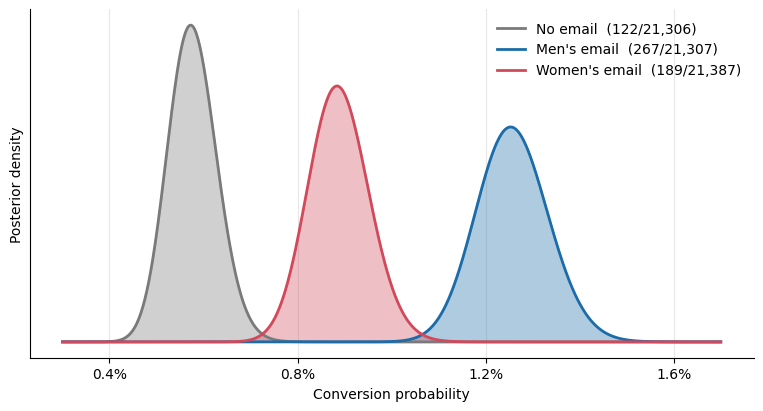

In [12]:
# Slide 11 chart: posterior density of each arm's conversion probability
grid = np.linspace(0.003, 0.017, 1000)
fig, ax = plt.subplots(figsize=(7.52, 4.0), constrained_layout=True)
for arm in ARMS:
    x = int(df[df.segment==arm].conversion.sum()); n = int((df.segment==arm).sum())
    density = post[arm].pdf(grid)
    ax.plot(grid, density, color=ARM_COLORS[arm], lw=2, label=f'{ARM_LABELS[arm]}  ({x}/{n:,})')
    ax.fill_between(grid, density, color=ARM_COLORS[arm], alpha=0.35)
ax.set(xlabel='Conversion probability', ylabel='Posterior density', yticks=[], xticks=[0.004, 0.008, 0.012, 0.016])
ax.xaxis.set_major_formatter(mticker.PercentFormatter(1.0, decimals=1))
ax.legend(frameon=False); tidy(ax, 'x')
fig.savefig(FIGURES / 'slide11_conversion_posteriors.png', dpi=200); plt.show()

### 3.4 Spend: bootstrap (slides 13–14)
99.1% of spend is zero with a long tail, so a normal model is wrong. Resample customers with replacement within each arm 5,000 times, recompute the difference of means, take the 2.5th and 97.5th percentiles.

Check: with about 21,000 customers per arm the bootstrap interval should match the Welch normal interval. We also show Bonferroni-adjusted intervals for the three pairwise comparisons: men's vs women's does not survive the adjustment, which is why the slide calls it marginal.

In [13]:
def boot_diff_mean(y1, y0, B=5000, seed=0):
    r = np.random.default_rng(seed); n1, n0 = len(y1), len(y0)
    d = np.array([y1[r.integers(0, n1, n1)].mean() - y0[r.integers(0, n0, n0)].mean() for _ in range(B)])
    return y1.mean() - y0.mean(), np.percentile(d, [2.5, 97.5])
sp = {a: y[t==i] for i, a in enumerate(ARMS)}
boot_results = {}
print({a: round(v.mean(), 2) for a, v in sp.items()}, '| skewness %.1f' % stats.skew(y))
for a,b in [('Mens E-Mail','No E-Mail'),('Womens E-Mail','No E-Mail'),('Mens E-Mail','Womens E-Mail')]:
    est, ci = boot_diff_mean(sp[a], sp[b]); boot_results[(a, b)] = (est, ci); print(f'{a} - {b}: {est:+.2f}  95% CI [{ci[0]:.2f}, {ci[1]:.2f}]')

{'No E-Mail': np.float64(0.65), 'Mens E-Mail': np.float64(1.42), 'Womens E-Mail': np.float64(1.08)} | skewness 20.6


Mens E-Mail - No E-Mail: +0.77  95% CI [0.49, 1.05]


Womens E-Mail - No E-Mail: +0.42  95% CI [0.18, 0.68]


Mens E-Mail - Womens E-Mail: +0.35  95% CI [0.03, 0.66]


In [14]:
# Check against the Welch normal interval; Bonferroni for three comparisons uses z = 2.394
for (a, b), (est, ci) in boot_results.items():
    se = np.sqrt(sp[a].var(ddof=1)/len(sp[a]) + sp[b].var(ddof=1)/len(sp[b]))
    print(f'{a} - {b}: bootstrap [{ci[0]:.2f}, {ci[1]:.2f}]   Welch [{est-1.96*se:.2f}, {est+1.96*se:.2f}]   '
          f'Bonferroni 98.3% [{est-2.394*se:.2f}, {est+2.394*se:.2f}]')

Mens E-Mail - No E-Mail: bootstrap [0.49, 1.05]   Welch [0.49, 1.05]   Bonferroni 98.3% [0.42, 1.12]
Womens E-Mail - No E-Mail: bootstrap [0.18, 0.68]   Welch [0.17, 0.68]   Bonferroni 98.3% [0.11, 0.74]
Mens E-Mail - Womens E-Mail: bootstrap [0.03, 0.66]   Welch [0.03, 0.66]   Bonferroni 98.3% [-0.04, 0.73]


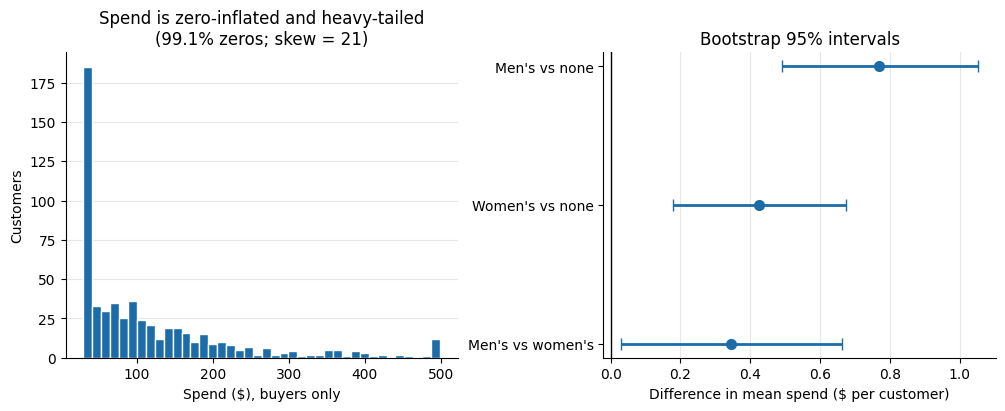

In [15]:
# Slide 13 chart: spend distribution among buyers, and the bootstrap intervals
fig, axs = plt.subplots(1, 2, figsize=(9.94, 4.0), constrained_layout=True)
axs[0].hist(y[y > 0], bins=40, color=ARM_COLORS['Mens E-Mail'], edgecolor='white')
axs[0].set(xlabel='Spend ($), buyers only', ylabel='Customers',
           title=f'Spend is zero-inflated and heavy-tailed\n({(y == 0).mean():.1%} zeros; skew = {stats.skew(y):.0f})')
tidy(axs[0])
labels = ["Men's vs none", "Women's vs none", "Men's vs women's"]
for row, ((a, b), (est, ci)) in enumerate(boot_results.items()):
    axs[1].errorbar(est, row, xerr=[[est - ci[0]], [ci[1] - est]], fmt='o', color=ARM_COLORS['Mens E-Mail'], capsize=4, lw=2, ms=7)
axs[1].set_yticks(range(3), labels); axs[1].invert_yaxis(); axs[1].axvline(0, color='black', lw=1)
axs[1].set(xlabel='Difference in mean spend ($ per customer)', title='Bootstrap 95% intervals'); tidy(axs[1], 'x')
fig.savefig(FIGURES / 'slide13_spend_bootstrap.png', dpi=200); plt.show()

### 3.5 Matching by past purchases (slides 15–16)
Inside each past-purchase group: average conversion and spend by email, and P(men's conversion > women's) from Beta draws.

In [16]:
grp = np.where((df.mens==1)&(df.womens==0), 'mens_only', np.where((df.mens==0)&(df.womens==1), 'womens_only', 'both'))
rows = []
for g in ['mens_only','womens_only','both']:
    m = grp == g; s = df[m]
    pm = beta_post(s[s.segment=='Mens E-Mail'].conversion.sum(), (s.segment=='Mens E-Mail').sum())
    pw = beta_post(s[s.segment=='Womens E-Mail'].conversion.sum(), (s.segment=='Womens E-Mail').sum())
    r = np.random.default_rng(0); pgt = (pm.rvs(400000, random_state=r) > pw.rvs(400000, random_state=r)).mean()
    rows.append(dict(group=g, n=m.sum(),
        **{f'conv% {k}': round(100*s[s.segment==a].conversion.mean(), 2) for a,k in zip(ARMS,['none','mens','womens'])},
        **{f'spend$ {k}': round(s[s.segment==a].spend.mean(), 2) for a,k in zip(ARMS,['none','mens','womens'])},
        P_mens_conv_gt_womens=round(pgt, 5)))
group_table = pd.DataFrame(rows).set_index('group')
group_table

,n,conv% none,conv% mens,conv% womens,spend$ none,spend$ mens,spend$ womens,P_mens_conv_gt_womens
group,,,,,,,,
mens_only,28818,0.55,1.15,0.61,0.70,1.38,0.97,0.99998
womens_only,28734,0.51,1.09,1.03,0.49,1.11,1.12,0.65971
both,6448,0.93,2.43,1.46,1.18,3.01,1.34,0.98884


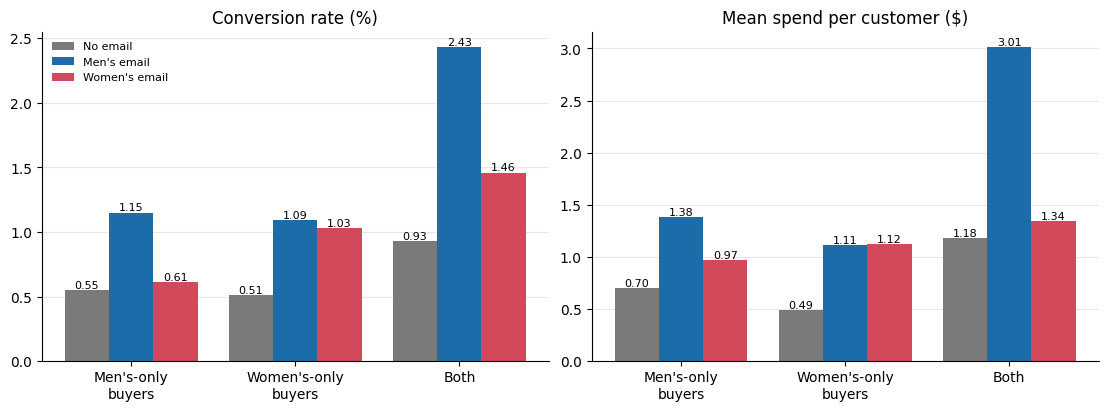

In [17]:
# Slide 15 chart: conversion and spend by past-purchase group and email
groups = ['mens_only', 'womens_only', 'both']; group_names = ["Men's-only\nbuyers", "Women's-only\nbuyers", 'Both']
fig, axs = plt.subplots(1, 2, figsize=(10.97, 4.0), constrained_layout=True)
for ax, prefix, title in [(axs[0], 'conv% ', 'Conversion rate (%)'), (axs[1], 'spend$ ', 'Mean spend per customer ($)')]:
    for k, (arm, key) in enumerate(zip(ARMS, ['none', 'mens', 'womens'])):
        bars = ax.bar(np.arange(3) + (k - 1)*0.27, group_table.loc[groups, prefix + key], 0.27,
                      color=ARM_COLORS[arm], label=ARM_LABELS[arm])
        ax.bar_label(bars, fmt='%.2f', fontsize=8)
    ax.set_xticks(range(3), group_names); ax.set_title(title); tidy(ax)
axs[0].legend(frameon=False, fontsize=8, loc='upper left')
fig.savefig(FIGURES / 'slide15_groups.png', dpi=200); plt.show()

### 3.6 The matching test (slides 17–18)
**Policy value** = 3 × average spend of customers whose *actual* email equals the policy's choice. The 3 is because each email had probability 1/3 inside every group. Interval: bootstrap of the per-customer difference (3,000). **Interaction** = (men's − women's spend gap among men's-only) − (same gap among women's-only), bootstrap 1,500.

We also report the analytic standard error of the mean difference and the **smallest gain the test could reliably detect** (80% power, 5% two-sided: about 2.8 standard errors). A non-significant result only rules out gains larger than that.

In [18]:
pol = np.where(grp == 'womens_only', 2, 1)              # matching: women's email to women's-only buyers, men's email otherwise
matched = 3 * y * (t == pol); allmen = 3 * y * (t == 1); diff = matched - allmen
rb = np.random.default_rng(6); bs = [diff[rb.integers(0, len(df), len(df))].mean() for _ in range(3000)]
print('matching policy  $%.3f' % matched.mean()); print("men's to all     $%.3f" % allmen.mean())
print('difference       $%+.3f  95%% CI [%.2f, %.2f]' % (diff.mean(), *np.percentile(bs, [2.5, 97.5])))
def inter(idx):
    o = []
    for g in ('mens_only','womens_only'):
        m = grp[idx]==g; tt = t[idx]; yy = y[idx]; o.append(yy[m&(tt==1)].mean() - yy[m&(tt==2)].mean())
    return o[0]-o[1]
rr = np.random.default_rng(7); bi = [inter(rr.integers(0, len(df), len(df))) for _ in range(1500)]
print('interaction      %.2f  95%% CI [%.2f, %.2f]' % (inter(np.arange(len(df))), *np.percentile(bi, [2.5, 97.5])))
se_diff = diff.std(ddof=1) / np.sqrt(len(diff))
print('analytic SE %.3f -> 95%% CI [%.2f, %.2f]' % (se_diff, diff.mean() - 1.96*se_diff, diff.mean() + 1.96*se_diff))
print('smallest gain detectable with 80%% power: about 2.8 x SE = $%.2f per customer (%.0f%% of the $%.2f baseline)'
      % (2.8*se_diff, 100*2.8*se_diff/allmen.mean(), allmen.mean()))

matching policy  $1.432
men's to all     $1.421
difference       $+0.011  95% CI [-0.17, 0.20]


interaction      0.42  95% CI [-0.24, 1.06]
analytic SE 0.094 -> 95% CI [-0.17, 0.20]
smallest gain detectable with 80% power: about 2.8 x SE = $0.26 per customer (19% of the $1.42 baseline)


### 3.7 Robustness: other prior and z-tests (slide 19)
Posterior mean with prior Beta(a, b) = (a + x)/(a + b + n). z = (p₁ − p₂)/√(p̂(1 − p̂)(1/n₁ + 1/n₂)) with pooled p̂.

In [19]:
for arm in ARMS:
    x = int(df[df.segment==arm].conversion.sum()); n = int((df.segment==arm).sum())
    print(f'{arm:14s} flat Beta(1,1): {beta_post(x,n).mean():.3%}   Beta(9,991): {beta_post(x,n,9,991).mean():.3%}')
def ztest(a, b):
    xa, na = df[df.segment==a].conversion.sum(), (df.segment==a).sum(); xb, nb = df[df.segment==b].conversion.sum(), (df.segment==b).sum()
    ph = (xa+xb)/(na+nb); z = (xa/na - xb/nb)/np.sqrt(ph*(1-ph)*(1/na+1/nb)); return z, 2*stats.norm.sf(abs(z))
for a,b in [('Mens E-Mail','No E-Mail'),('Womens E-Mail','No E-Mail'),('Mens E-Mail','Womens E-Mail')]:
    print(a, 'vs', b, 'z = %.2f, p = %.2g' % ztest(a, b))

No E-Mail      flat Beta(1,1): 0.577%   Beta(9,991): 0.587%
Mens E-Mail    flat Beta(1,1): 1.258%   Beta(9,991): 1.237%
Womens E-Mail  flat Beta(1,1): 0.888%   Beta(9,991): 0.884%
Mens E-Mail vs No E-Mail z = 7.39, p = 1.5e-13
Womens E-Mail vs No E-Mail z = 3.78, p = 0.00016
Mens E-Mail vs Womens E-Mail z = 3.71, p = 0.00021


### 3.8 Robustness: lasso with interactions, evaluated on held-out folds (slide 20)
Features: 9 customer characteristics + 2 arm indicators + 18 arm × characteristic interactions (29). 5-fold CV picks the penalty. The policy picks, for each held-out customer, the email with the highest predicted spend; its value is computed as in 3.6 using only customers in the held-out fold.

The learned policy may choose any of the three options, including no email. The 95% interval bootstraps the per-customer difference (learned minus men's email to all) pooled over the held-out folds, as in 3.6. Each fold has its own lasso, so we report how many of the 29 coefficients each held-out model keeps. The CV curve on the slide comes from one extra lasso fit to all the data; it is used only for that chart, not for the policy value. Features are standardized on the full data before splitting; this uses no outcomes, so it cannot leak them.

In [20]:

from sklearn.linear_model import LassoCV
from sklearn.model_selection import KFold
X = pd.get_dummies(df[['zip_code','channel']], drop_first=True).astype(float)
X['recency']=df.recency; X['history']=np.log(df.history); X['mens']=df.mens; X['womens']=df.womens; X['newbie']=df.newbie
X = (X - X.mean())/X.std()
def inter_matrix(X, t):
    cols = [X.values]
    for a in (1, 2): cols += [(t==a)[:,None]*1.0, (t==a)[:,None]*X.values]
    return np.hstack(cols)
vals, base, nonzero_per_fold = [], [], []
learned_minus_mens = np.empty(len(df))      # per-customer difference, filled in fold by fold
learned_choice = np.empty(len(df), dtype=int)
for tr, te in KFold(5, shuffle=True, random_state=0).split(X):
    m = LassoCV(cv=5, random_state=0, n_jobs=-1).fit(inter_matrix(X.iloc[tr], t[tr]), y[tr])
    nonzero_per_fold.append(int((m.coef_ != 0).sum()))
    pred = np.column_stack([m.predict(inter_matrix(X.iloc[te], np.full(len(te), a))) for a in range(3)])
    choice = pred.argmax(1); learned_choice[te] = choice
    vals.append(3*(y[te]*(choice==t[te])).sum()/len(te)); base.append(3*(y[te]*(t[te]==1)).sum()/len(te))
    learned_minus_mens[te] = 3*y[te]*(choice==t[te]) - 3*y[te]*(t[te]==1)
print('learned policy $%.2f   men\'s email to all $%.2f   difference $%+.2f' % (np.mean(vals), np.mean(base), np.mean(vals)-np.mean(base)))
rb = np.random.default_rng(6); bs = [learned_minus_mens[rb.integers(0, len(df), len(df))].mean() for _ in range(3000)]
print('difference 95%% CI (bootstrap, 3,000 resamples) [%.2f, %.2f]' % tuple(np.percentile(bs, [2.5, 97.5])))
print('nonzero coefficients (of 29) in the five held-out models:', nonzero_per_fold)
print("learned policy sends: no email %.1f%%, men's %.1f%%, women's %.1f%%" % tuple(100*np.bincount(learned_choice, minlength=3)/len(df)))
lasso_all = LassoCV(cv=5, random_state=0, n_jobs=-1).fit(inter_matrix(X, t), y)   # used only for the CV-curve chart
print('lasso fit on all data (CV-curve chart): penalty %.4f, nonzero coefficients %d of 29' % (lasso_all.alpha_, (lasso_all.coef_ != 0).sum()))

learned policy $1.37   men's email to all $1.42   difference $-0.06


difference 95% CI (bootstrap, 3,000 resamples) [-0.20, 0.08]
nonzero coefficients (of 29) in the five held-out models: [21, 16, 22, 25, 17]
learned policy sends: no email 0.6%, men's 74.6%, women's 24.8%


lasso fit on all data (CV-curve chart): penalty 0.0186, nonzero coefficients 19 of 29


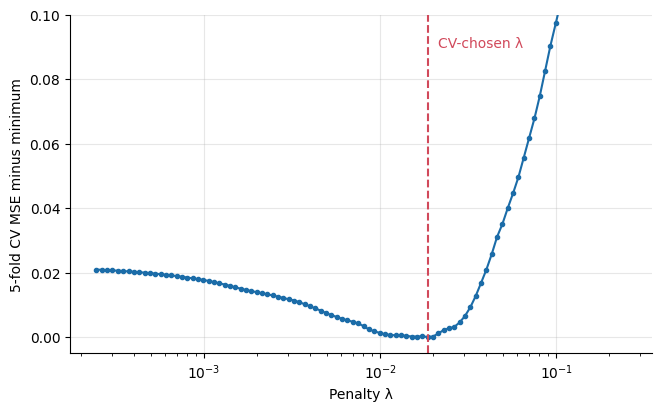

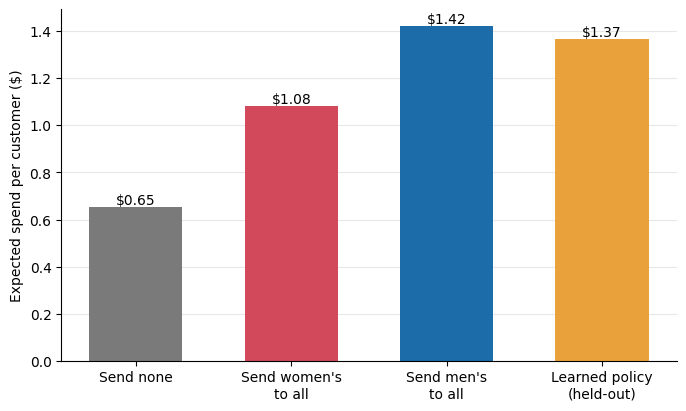

In [21]:
# Slide 20 charts: lasso CV curve (left) and policy values (right)
fig, ax = plt.subplots(figsize=(6.5, 4.0), constrained_layout=True)
cv_mse = lasso_all.mse_path_.mean(axis=1)
ax.plot(lasso_all.alphas_, cv_mse - cv_mse.min(), 'o-', ms=3, color=ARM_COLORS['Mens E-Mail'])
ax.axvline(lasso_all.alpha_, color=ARM_COLORS['Womens E-Mail'], ls='--')
ax.text(lasso_all.alpha_*1.15, 0.09, 'CV-chosen λ', color=ARM_COLORS['Womens E-Mail'])
ax.set(xscale='log', xlabel='Penalty λ', ylabel='5-fold CV MSE minus minimum', ylim=(-0.005, 0.1)); tidy(ax, 'both')
fig.savefig(FIGURES / 'slide20_lasso_cv.png', dpi=200); plt.show()

policy_values = {'Send none': (3*y*(t==0)).mean(), "Send women's\nto all": (3*y*(t==2)).mean(),
                 "Send men's\nto all": (3*y*(t==1)).mean(), 'Learned policy\n(held-out)': np.mean(vals)}
fig, ax = plt.subplots(figsize=(6.75, 4.0), constrained_layout=True)
bars = ax.bar(range(4), list(policy_values.values()), width=0.6,
              color=[ARM_COLORS['No E-Mail'], ARM_COLORS['Womens E-Mail'], ARM_COLORS['Mens E-Mail'], LEARNED_COLOR])
ax.bar_label(bars, labels=[f'${v:.2f}' for v in policy_values.values()])
ax.set_xticks(range(4), list(policy_values.keys())); ax.set(ylabel='Expected spend per customer ($)'); tidy(ax)
fig.savefig(FIGURES / 'slide20_policy_values.png', dpi=200); plt.show()

## 4. Conclusion
Send the men's email: conversion rises from 0.58% to 1.26% (P(men's > women's) > 0.9999) and spend by about $0.77 per customer [0.49, 1.05]. Matching to past purchases gives $1.43 vs $1.42 (difference +$0.01, 95% CI [−0.17, +0.20]): **no detectable gain**. The test could only reliably detect gains of about $0.26 per customer, so a small benefit cannot be ruled out. A lasso that learns its own targeting rule does no better on held-out customers (−$0.06, 95% CI [−0.20, +0.08]).

## 5. Sanity checks for the key functions
Each check uses a case where the right answer is known. Every `assert` must pass; the last line prints when they all do.

In [22]:
# beta_post: the conjugate formula equals prior x likelihood, normalized numerically on a grid
p_grid = np.linspace(1e-6, 0.05, 200_001); x_test, n_test = 7, 1000
unnormalized = stats.beta(1, 1).pdf(p_grid) * stats.binom.pmf(x_test, n_test, p_grid)
numerical_posterior = unnormalized / np.trapezoid(unnormalized, p_grid)
assert np.allclose(numerical_posterior, beta_post(x_test, n_test).pdf(p_grid), atol=1e-3 * numerical_posterior.max())
assert np.isclose(beta_post(x_test, n_test).mean(), (1 + x_test) / (2 + n_test))

# boot_diff_mean: on normal data the bootstrap interval matches the textbook interval
r = np.random.default_rng(1); sample_a = r.normal(1.0, 2.0, 5000); sample_b = r.normal(0.5, 2.0, 5000)
est_test, ci_test = boot_diff_mean(sample_a, sample_b, B=2000)
se_test = np.sqrt(sample_a.var(ddof=1)/5000 + sample_b.var(ddof=1)/5000)
assert np.isclose(est_test, sample_a.mean() - sample_b.mean())
assert np.allclose(ci_test, [est_test - 1.96*se_test, est_test + 1.96*se_test], atol=0.25*se_test)

# Weight-3 policy value: unbiased in a simulated 3-arm experiment whose true policy value is known
r = np.random.default_rng(2); n_sim = 300_000
group_sim = r.integers(0, 2, n_sim); arm_sim = r.integers(0, 3, n_sim)     # arms assigned with probability 1/3
true_mean = np.array([[0.6, 0.5], [1.4, 1.0], [1.0, 1.3]])                # true_mean[arm, group]
spend_sim = r.exponential(true_mean[arm_sim, group_sim])
policy_sim = np.where(group_sim == 1, 2, 1)                                # women's email to group 1, men's otherwise
true_value = true_mean[policy_sim, group_sim].mean()
weighted = 3 * spend_sim * (arm_sim == policy_sim)
assert abs(weighted.mean() - true_value) < 4 * weighted.std() / np.sqrt(n_sim)

# Interaction: equals the gap-of-gaps read straight off the group means
gap = lambda g: y[(grp == g) & (t == 1)].mean() - y[(grp == g) & (t == 2)].mean()
assert np.isclose(inter(np.arange(len(df))), gap('mens_only') - gap('womens_only'))

# Lasso design: 9 characteristics + 2 arm indicators + 18 interactions = 29 columns; arm 0 has no arm terms
design = inter_matrix(X.iloc[:5], np.zeros(5, dtype=int))
assert design.shape == (5, 29) and np.all(design[:, 9:] == 0)

# Matching vs men's-to-all differ only for women's-only buyers
assert np.all(diff[grp != 'womens_only'] == 0)
print('All sanity checks passed.')

All sanity checks passed.
